# 04 · Variograma y kriging: reconstruir lo que ocultan las nubes

El compuesto de 12 escenas por año ya elimina casi todos los vacíos por nubes. Pero en monitoreo **casi en tiempo
real** (una o pocas escenas) las nubes tapan grandes zonas. Para medir cuánto puede recuperar la geoestadística se
diseña un **experimento de oclusión**:

1. Se ocultan zonas con **nubes simuladas** (discos de 1.5-4 km hasta cubrir el 15 % de los hexágonos).
2. Con los hexágonos visibles se estima el variograma empírico (Matheron) y se ajustan modelos teóricos.
3. **Kriging ordinario** con vecindario móvil reconstruye las zonas ocultas.
4. Se compara contra el **valor real** (que sí conocemos) y contra IDW, y se evalúa si la varianza de kriging
   describe bien el error (cobertura del intervalo al 95 %).

$$\hat\gamma(h) = \frac{1}{2N(h)}\sum_{N(h)}[Z(s_i) - Z(s_j)]^2$$

In [0]:
%pip install -q rasterio pyproj h3 geopandas shapely esda libpysal spreg pykrige scikit-gstat mapclassify
dbutils.library.restartPython()

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import sys, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Raíz del repositorio (Git folder en Databricks o clon local)
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))

from geocloud import config as C, dbx
spark = dbx.get_spark()
VOL = dbx.volume_path()
FIG = Path(VOL) / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Databricks:", dbx.is_databricks(), "| Volume:", VOL)

Databricks: True | Volume: /Volumes/workspace/madre_dios_rs/raw


In [0]:
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from geocloud import spatial

feat = spark.table(dbx.tbl("gold_h3_features")).toPandas().pipe(dbx.clean)
YEARS = sorted(int(c.split("_")[1]) for c in feat.columns if c.startswith("ndvi_") and c.split("_")[1].isdigit())
Y0, Y1 = YEARS[0], YEARS[-1]
gdf = spatial.h3_to_geodataframe(feat, crs_out=C.CRS_UTM)
# Hexágonos de bosque: al menos la mitad de su superficie era bosque en el año base (excluye ríos, poblados, no bosque)
BOSQUE = gdf["frac_bosque_y0"] >= 0.5 if "frac_bosque_y0" in gdf else pd.Series(True, index=gdf.index)
print(f"Hexágonos: {len(gdf):,} | de bosque en {Y0}: {BOSQUE.sum():,} | años: {YEARS}")

Hexágonos: 21,854 | de bosque en 2018: 16,601 | años: [2018, 2020, 2022, 2024, 2025]


In [0]:
# Capas de contexto cartográfico (leyenda, topónimos, escala y norte)
vec = Path(VOL) / "bronze" / "vector"
def capa(n):
    p = vec / f"{n}.geojson"
    return gpd.read_file(p).to_crs(C.CRS_UTM) if p.exists() else None

rios, vias, za, poblados = capa("rios"), capa("vias"), capa("zonas_amortiguamiento"), capa("poblados")
anp = capa("areas_protegidas_sernanp")
anp = anp if anp is not None else capa("areas_protegidas")
if vias is not None and "highway" in vias:
    vias = vias[vias["highway"].isin(["trunk", "primary"])]
if poblados is not None and len(poblados) > 15:
    poblados = poblados[poblados["fclass"].isin(["city", "town"])] if "fclass" in poblados else poblados.head(12)
BOUNDS = C.GRID_BOUNDS_UTM
CONTEXTO = {"Ríos": (rios, dict(color="#1f78b4", lw=0.8)),
            "Vía principal (Interoceánica)": (vias, dict(color="black", lw=1.1)),
            "ANP (SERNANP)": (anp, dict(color="purple", lw=1.1)),
            "Zona de amortiguamiento": (za, dict(color="darkorange", lw=1.0, ls="--"))}

def contexto(ax, legend=True, **kw):
    spatial.decorate_map(ax, BOUNDS, CONTEXTO, poblados, legend=legend, **kw)

In [0]:
VAR = f"ndvi_{Y1}"
obs = gdf.dropna(subset=[VAR]).reset_index(drop=True)
xy = obs[["x_km", "y_km"]].values

# Nubes simuladas: discos aleatorios hasta ocultar el 15 % de los hexágonos
rng = np.random.default_rng(42)
oculto = np.zeros(len(obs), dtype=bool)
nubes = []
while oculto.mean() < 0.15:
    c, r = xy[rng.integers(len(xy))], rng.uniform(1.5, 4.0)
    oculto |= np.hypot(*(xy - c).T) < r
    nubes.append((c, r))
obs["oculto"] = oculto
visibles, ocultos = obs[~oculto], obs[oculto]
print(f"Hexágonos: {len(obs):,} | ocultos por {len(nubes)} nubes simuladas: {oculto.sum():,} ({oculto.mean():.1%})")

Hexágonos: 21,854 | ocultos por 16 nubes simuladas: 3,406 (15.6%)


## 1. Variograma empírico y modelos teóricos (solo con hexágonos visibles)

In [0]:
import skgstat as skg

s = visibles.iloc[rng.choice(len(visibles), size=min(3000, len(visibles)), replace=False)]
coords, vals = s[["x_km", "y_km"]].values, s[VAR].values
nombres = {"spherical": "esférico", "exponential": "exponencial", "gaussian": "gaussiano"}
modelos = {}
for m in nombres:
    V = skg.Variogram(coords, vals, model=m, n_lags=25, maxlag=20, use_nugget=True)
    rng_, sill, nug = V.parameters[:3]
    modelos[m] = {"modelo": nombres[m], "rango_km": rng_, "meseta_parcial": sill, "pepita": nug,
                  "meseta_total": sill + nug, "pepita/meseta": nug / (sill + nug), "RMSE_ajuste": V.rmse, "obj": V}
tab = pd.DataFrame(modelos).T.drop(columns="obj").sort_values("RMSE_ajuste")
best = tab.index[0]
print(tab.set_index("modelo").round(4))

              rango_km meseta_parcial  ... pepita/meseta RMSE_ajuste
modelo                                 ...                          
esférico     14.125099       0.048405  ...      0.277496    0.001782
exponencial  17.329939       0.059559  ...      0.157175    0.002022
gaussiano    13.753166       0.041835  ...      0.375979    0.002583

[3 rows x 6 columns]


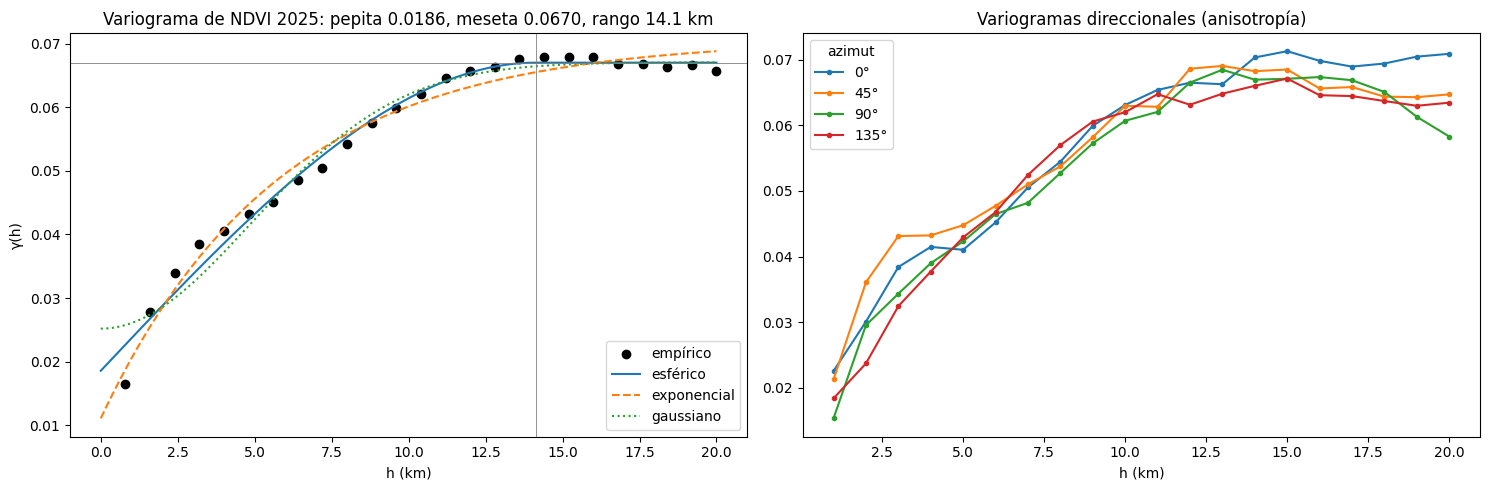

In [0]:
V = modelos[best]["obj"]
h = np.linspace(0, V.bins.max(), 200)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(V.bins, V.experimental, "o", c="k", label="empírico")
for m, sty in zip(modelos, ["-", "--", ":"]):
    ax[0].plot(h, modelos[m]["obj"].fitted_model(h), sty, label=nombres[m])
r, ps, n0 = modelos[best]["rango_km"], modelos[best]["meseta_parcial"], modelos[best]["pepita"]
ax[0].axhline(ps + n0, c="grey", lw=0.6); ax[0].axvline(r, c="grey", lw=0.6)
ax[0].set_xlabel("h (km)"); ax[0].set_ylabel("γ(h)"); ax[0].legend()
ax[0].set_title(f"Variograma de NDVI {Y1}: pepita {n0:.4f}, meseta {ps+n0:.4f}, rango {r:.1f} km")
for az, c in [(0, "C0"), (45, "C1"), (90, "C2"), (135, "C3")]:
    DV = skg.DirectionalVariogram(coords, vals, azimuth=az, tolerance=22.5, n_lags=20, maxlag=20)
    ax[1].plot(DV.bins, DV.experimental, "o-", c=c, ms=3, label=f"{az}°")
ax[1].set_xlabel("h (km)"); ax[1].set_title("Variogramas direccionales (anisotropía)"); ax[1].legend(title="azimut")
plt.tight_layout(); plt.savefig(FIG / "04_variogramas.png", dpi=150); plt.show()

**Lectura:** la razón pepita/meseta mide qué parte de la variabilidad no tiene estructura espacial a la escala de
un hexágono (menos de 25 % indica dependencia espacial fuerte). El rango es la distancia a partir de la cual dos
hexágonos dejan de parecerse. Si los variogramas direccionales coinciden, el proceso es aproximadamente isotrópico.

## 2. Reconstrucción de las zonas ocultas: kriging ordinario vs IDW

In [0]:
from pykrige.ok import OrdinaryKriging
from scipy.spatial import cKDTree

km = best if best in ("spherical", "exponential") else "spherical"
p = modelos[km]
vparams = {"sill": p["meseta_total"], "range": p["rango_km"], "nugget": p["pepita"]}
train = visibles.iloc[rng.choice(len(visibles), size=min(8000, len(visibles)), replace=False)]

ok = OrdinaryKriging(train.x_km, train.y_km, train[VAR], variogram_model=km, variogram_parameters=vparams)
z_ok, ss_ok = ok.execute("points", ocultos.x_km.values, ocultos.y_km.values, backend="loop", n_closest_points=50)
z_ok, sd_ok = np.asarray(z_ok), np.sqrt(np.asarray(ss_ok))

tree = cKDTree(visibles[["x_km", "y_km"]].values)
dd, ii = tree.query(ocultos[["x_km", "y_km"]].values, k=12)
wts = 1 / np.maximum(dd, 1e-6) ** 2
z_idw = (wts * visibles[VAR].values[ii]).sum(1) / wts.sum(1)

real = ocultos[VAR].values
def met(zhat):
    e = zhat - real
    return {"RMSE": np.sqrt(np.mean(e**2)), "MAE": np.mean(np.abs(e)),
            "R2": 1 - np.sum(e**2) / np.sum((real - real.mean())**2), "sesgo": e.mean()}
cv = pd.DataFrame({"Kriging ordinario": met(z_ok), "IDW (p=2, k=12)": met(z_idw)}).T
cobertura = np.mean(np.abs(z_ok - real) <= 1.96 * sd_ok)
print(cv.round(4))
print(f"Cobertura del intervalo de kriging al 95 %: {cobertura:.1%} (ideal ≈ 95 %)")

                     RMSE     MAE      R2   sesgo
Kriging ordinario  0.1879  0.1262  0.0131 -0.0393
IDW (p=2, k=12)    0.1973  0.1220 -0.0877 -0.0350
Cobertura del intervalo de kriging al 95 %: 89.8% (ideal ≈ 95 %)


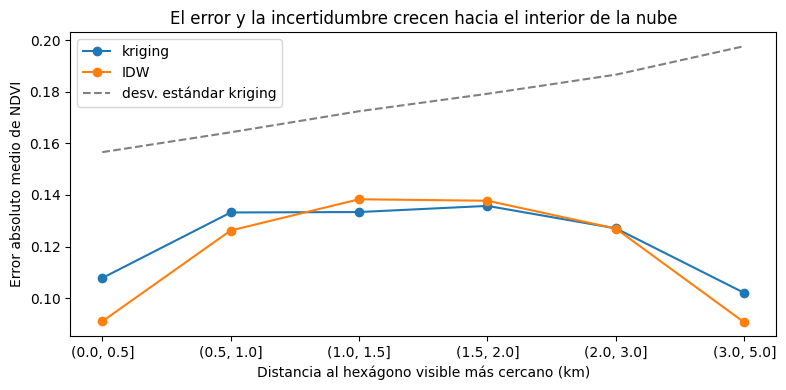

            kriging     IDW  sd_kriging
banda                                  
(0.0, 0.5]   0.1078  0.0910      0.1566
(0.5, 1.0]   0.1332  0.1262      0.1643
(1.0, 1.5]   0.1334  0.1383      0.1725
(1.5, 2.0]   0.1358  0.1378      0.1793
(2.0, 3.0]   0.1271  0.1270      0.1867
(3.0, 5.0]   0.1020  0.0906      0.1977


In [0]:
# El error crece hacia el centro de la nube: distancia al hexágono visible más cercano
d_vis = dd[:, 0]
bandas = pd.cut(d_vis, [0, 0.5, 1, 1.5, 2, 3, 5])
err = pd.DataFrame({"banda": bandas, "kriging": np.abs(z_ok - real), "IDW": np.abs(z_idw - real), "sd_kriging": sd_ok})
t_err = err.groupby("banda", observed=True).mean()
ax = t_err[["kriging", "IDW"]].plot(marker="o", figsize=(8, 4))
t_err["sd_kriging"].plot(ax=ax, ls="--", c="grey", label="desv. estándar kriging")
ax.set_xlabel("Distancia al hexágono visible más cercano (km)"); ax.set_ylabel("Error absoluto medio de NDVI")
ax.set_title("El error y la incertidumbre crecen hacia el interior de la nube"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "04_error_distancia.png", dpi=150); plt.show()
print(t_err.round(4))

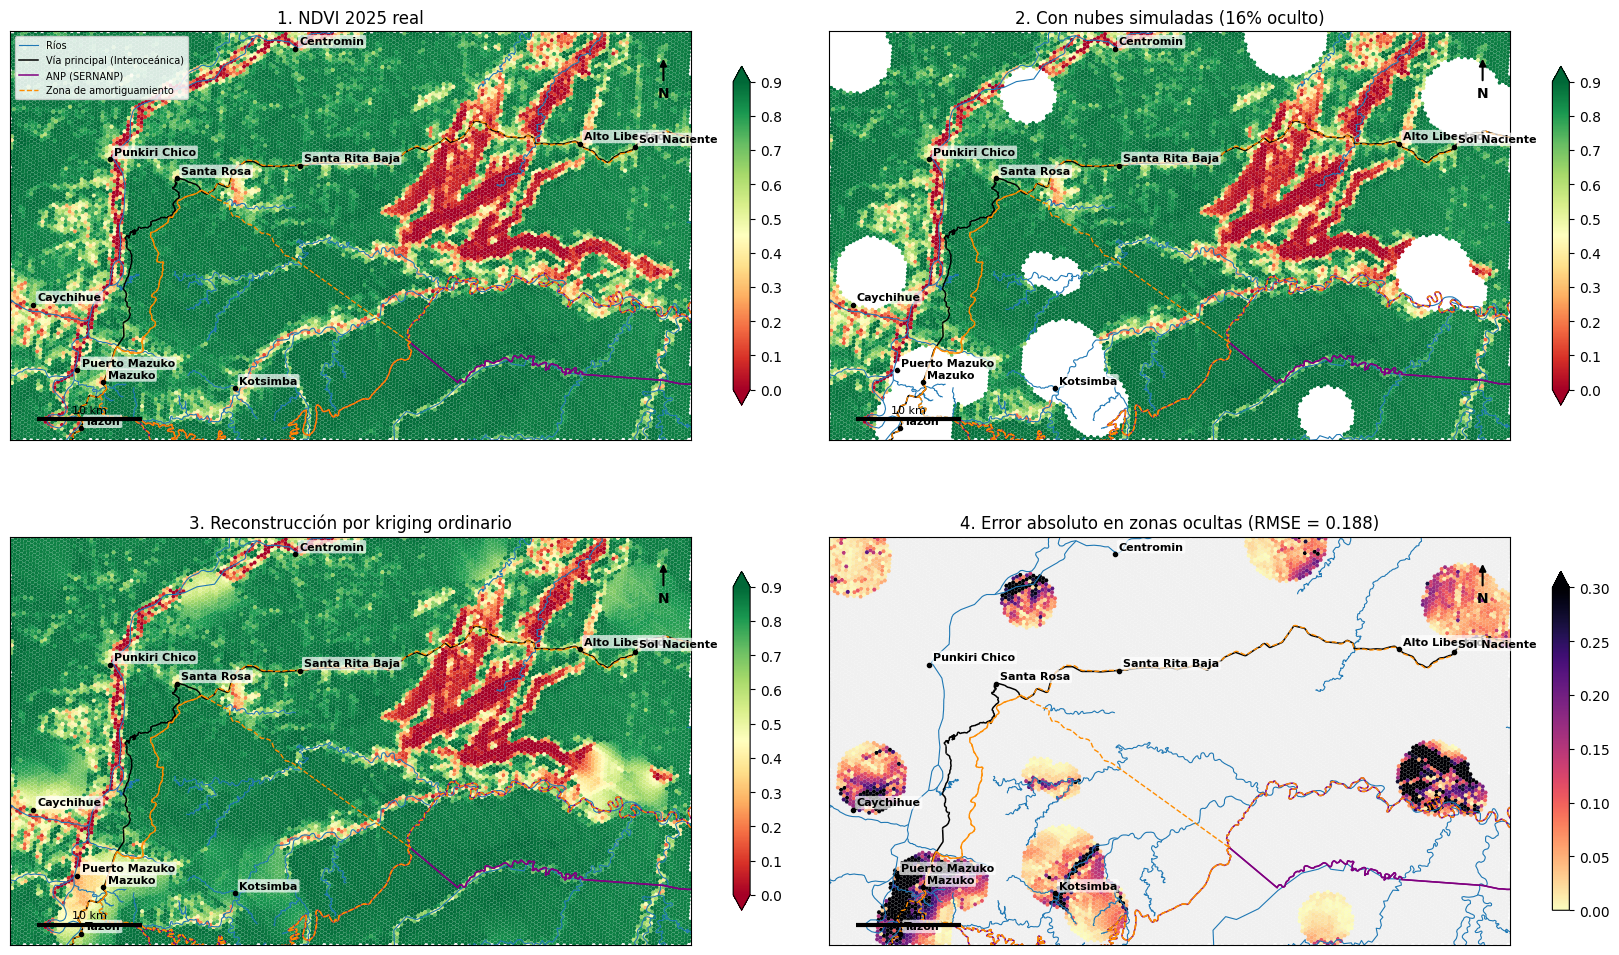

In [0]:
obs["ndvi_reconstruido"] = obs[VAR].where(~obs.oculto)
obs.loc[obs.oculto, "ndvi_reconstruido"] = z_ok
obs["krig_sd"] = 0.0
obs.loc[obs.oculto, "krig_sd"] = sd_ok
obs["error_abs"] = np.nan
obs.loc[obs.oculto, "error_abs"] = np.abs(z_ok - real)
G = gpd.GeoDataFrame(obs, geometry="geometry", crs=C.CRS_UTM)

fig, ax = plt.subplots(2, 2, figsize=(17, 11))
G.plot(column=VAR, cmap="RdYlGn", vmin=0, vmax=0.9, linewidth=0, ax=ax[0, 0], legend=True, legend_kwds={"shrink": 0.6})
ax[0, 0].set_title(f"1. NDVI {Y1} real")
G[~G.oculto].plot(column=VAR, cmap="RdYlGn", vmin=0, vmax=0.9, linewidth=0, ax=ax[0, 1], legend=True, legend_kwds={"shrink": 0.6})
G[G.oculto].plot(color="white", linewidth=0, ax=ax[0, 1])
ax[0, 1].set_title(f"2. Con nubes simuladas ({oculto.mean():.0%} oculto)")
G.plot(column="ndvi_reconstruido", cmap="RdYlGn", vmin=0, vmax=0.9, linewidth=0, ax=ax[1, 0], legend=True, legend_kwds={"shrink": 0.6})
ax[1, 0].set_title("3. Reconstrucción por kriging ordinario")
G.plot(color="#f0f0f0", linewidth=0, ax=ax[1, 1])
G[G.oculto].plot(column="error_abs", cmap="magma_r", vmin=0, vmax=0.3, linewidth=0, ax=ax[1, 1], legend=True,
                 legend_kwds={"shrink": 0.6})
ax[1, 1].set_title(f"4. Error absoluto en zonas ocultas (RMSE = {cv.loc['Kriging ordinario', 'RMSE']:.3f})")
for i, a in enumerate(ax.ravel()):
    contexto(a, legend=(i == 0))
plt.tight_layout(); plt.savefig(FIG / "04_kriging.png", dpi=150); plt.show()

In [0]:
# Vacíos reales por nubes en el compuesto (si existieran): se rellenan con el mismo modelo
reales = gdf[gdf[VAR].isna()]
if len(reales):
    zr, sr = ok.execute("points", reales.x_km.values, reales.y_km.values, backend="loop", n_closest_points=50)
    print(f"Vacíos reales rellenados: {len(reales):,}")
else:
    print("El compuesto de temporada seca no dejó vacíos reales: la reconstrucción se evalúa con la oclusión simulada.")
dbx.save_table(spark.createDataFrame(pd.DataFrame(obs[["h3", VAR, "oculto", "ndvi_reconstruido", "krig_sd", "error_abs"]])),
               "gold_h3_ndvi_kriging")

El compuesto de temporada seca no dejó vacíos reales: la reconstrucción se evalúa con la oclusión simulada.


'workspace.madre_dios_rs.gold_h3_ndvi_kriging'